# 02 - Merging into daily, seasonal and yearly tables

**Goal:** combine the cleaned tables into the datasets the analysis and the model use.

* **Daily** - one row per region per day. This is the master table.
* **Seasonal** - one row per region per Ethiopian season (Bega Oct-Jan, Belg Feb-May, Kiremt Jun-Sep).
* **Yearly** - one row per region per year.

Rain (CHIRPS) is the backbone: every other table is attached to it with a **left join**, so no rainy day is ever lost.
Where another dataset has no value (for example SMAP before 2015), the cell stays **empty**.

In [11]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Find ML/Src/processing from wherever the notebook is opened (ML/Notebooks or the project root)
here = Path.cwd().resolve()
candidates = [here, here.parent, here / "ML", here.parent / "ML", *here.parents]
PROC_SRC = next((c / "Src" / "processing" for c in candidates
                 if (c / "Src" / "processing" / "pipeline_common.py").exists()), None)
assert PROC_SRC is not None, "Could not find Src/processing - open this notebook from the ML/Notebooks folder."
sys.path.insert(0, str(PROC_SRC))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pipeline_common import (RAW_DIR, PROC_DIR, DATA_DIR, REGIONS, REGION_NAMES,
                             read_region_files, read_static_file, load_table, save_table, longest_run)
import label_config as cfg

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"Arsi": "#1f77b4", "Bale": "#d62728", "Jimma": "#2ca02c"}
FIG_DIR = DATA_DIR.parent / "Figures"
FIG_DIR.mkdir(exist_ok=True)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

print("Raw data :", RAW_DIR)
print("Processed:", PROC_DIR)
print("Figures  :", FIG_DIR)

Raw data : C:\hackaton\ML\Data\Raw
Processed: C:\hackaton\ML\Data\Processed
Figures  : C:\hackaton\ML\Figures


In [12]:
import merge_daily as md

## 1. Load the cleaned tables

In [13]:
rain = load_table("rainfall_daily")
weather = load_table("weather_daily")
soil = load_table("soil_moisture_daily")
static = load_table("static_context", parse_dates=())

for name, t in [("rain", rain), ("weather", weather), ("soil moisture", soil)]:
    print(f"{name:<14} rows={len(t):>6}   {t['date'].min().date()} -> {t['date'].max().date()}")
print("static rows:", len(static))

rain           rows= 50127   1981-01-01 -> 2026-09-30
weather        rows= 50250   1981-01-01 -> 2026-11-10
soil moisture  rows= 50256   1981-01-01 -> 2026-11-12
static rows: 3


The tables end on different dates because each satellite or model publishes with a different delay. The rain table sets the date range of the merged table.

## 2. Join step by step
After every join the row count must stay the same. If it grows, there are duplicates; if it shrinks, we lost days.

In [14]:
step = rain
print("rain only        ", step.shape)
step = step.merge(weather, on=["date", "region"], how="left")
print("+ weather        ", step.shape)
step = step.merge(soil, on=["date", "region"], how="left")
print("+ soil moisture  ", step.shape)
keep = [c for c in md.STATIC_KEEP if c in static.columns]
step = step.merge(static[["region"] + keep], on="region", how="left")
print("+ static context ", step.shape)

rain only         (50127, 4)
+ weather         (50127, 12)
+ soil moisture   (50127, 21)
+ static context  (50127, 29)


In [15]:
integrated = md.build_integrated_daily(rain, weather, soil, static)   # same logic, plus duplicate check

n_days = (integrated["date"].max() - integrated["date"].min()).days + 1
print("rows:", len(integrated), "| expected:", len(REGION_NAMES) * n_days)
assert len(integrated) == len(REGION_NAMES) * n_days, "a region-day is missing or duplicated"
print("duplicate region-days:", int(integrated.duplicated(["region", "date"]).sum()))
integrated.head()

rows: 50127 | expected: 50127
duplicate region-days: 0


,date,region,rain_mm,wet_day,t2m_c,tmax_c,tmin_c,rh_pct,wind10_ms,rad_mj,vpd_kpa,et0_mm,sm_l1,sm_l2,sm_l3,sm_l4,smap_l3_am,smap_l3_pm,smap_l3_sm,smap_l4_surface,smap_l4_rootzone,elevation_mean,slope_mean,cropland_fraction,clay_0_5cm_mean,sand_0_5cm_mean,silt_0_5cm_mean,soc_0_5cm_mean,bdod_0_5cm_mean,year,month,doy
0,1981-01-01,Arsi,0.000000,0.0,13.17,23.60,4.45,42.10,2.57,NaN,1.086321,NaN,0.253669,0.295016,0.351405,0.462937,NaN,NaN,NaN,NaN,NaN,2923.05094,6.681925,0.660192,34.169629,30.198802,35.631525,50.033644,1.110033,1981,1,1
1,1981-01-02,Arsi,7.135868,1.0,13.22,23.02,4.75,45.91,3.26,NaN,0.992563,NaN,0.255760,0.294499,0.350823,0.462535,NaN,NaN,NaN,NaN,NaN,2923.05094,6.681925,0.660192,34.169629,30.198802,35.631525,50.033644,1.110033,1981,1,2
2,1981-01-03,Arsi,0.000000,0.0,13.88,23.30,6.08,50.06,2.79,NaN,0.949140,NaN,0.259294,0.294001,0.350252,0.462134,NaN,NaN,NaN,NaN,NaN,2923.05094,6.681925,0.660192,34.169629,30.198802,35.631525,50.033644,1.110033,1981,1,3
3,1981-01-04,Arsi,0.483773,0.0,13.73,22.83,7.01,51.04,3.16,NaN,0.926134,NaN,0.260770,0.293512,0.349661,0.461731,NaN,NaN,NaN,NaN,NaN,2923.05094,6.681925,0.660192,34.169629,30.198802,35.631525,50.033644,1.110033,1981,1,4
4,1981-01-05,Arsi,0.070040,0.0,13.22,22.49,5.61,49.26,3.81,NaN,0.921969,NaN,0.260368,0.293034,0.349059,0.461325,NaN,NaN,NaN,NaN,NaN,2923.05094,6.681925,0.660192,34.169629,30.198802,35.631525,50.033644,1.110033,1981,1,5


## 3. What is empty, and when?
Rain, POWER and ERA5-Land should be nearly complete. SMAP only exists from 2015, so it is empty before that - **that is expected, not an error.**

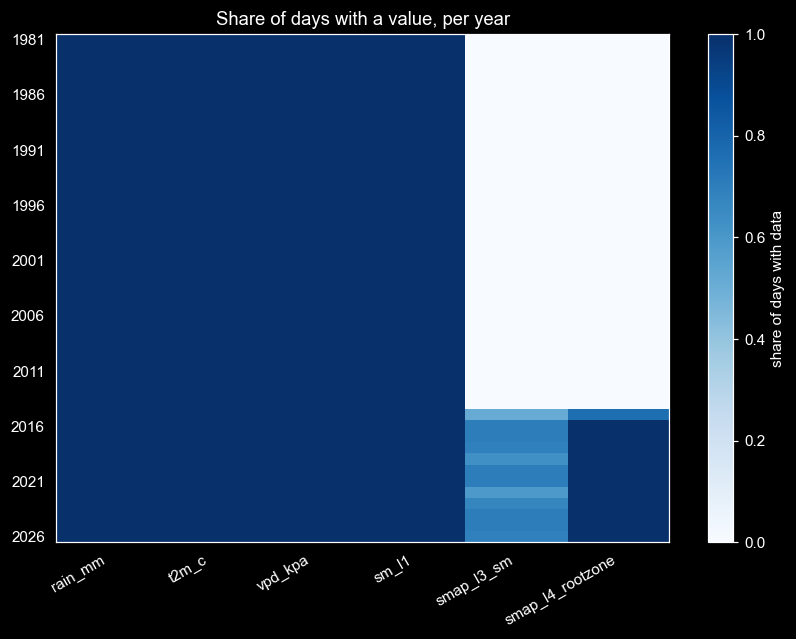

In [16]:
cols = ["rain_mm", "t2m_c", "vpd_kpa", "sm_l1", "smap_l3_sm", "smap_l4_rootzone"]
cover = integrated.groupby("year")[cols].apply(lambda g: g.notna().mean()).round(2)

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(cover.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=30, ha="right")
ax.set_yticks(range(0, len(cover), 5), cover.index[::5])
ax.set_title("Share of days with a value, per year")
ax.grid(False)
plt.colorbar(im, label="share of days with data")
savefig("merge_data_coverage")
plt.show()

## 4. Seasonal table
One row per region per season. `complete` is True only when every day of the season was observed, so partial seasons at the end of the data are not mistaken for dry seasons.

,region,season_year,season,days_in_period,days_observed,rain_total_mm,wet_days,max_dry_run_days,t2m_mean_c,tmax_mean_c,vpd_mean_kpa,et0_total_mm,sm_l1_mean,sm_l2_mean,complete
0,Arsi,1980,bega,31,31,7.689681,1.0,29,13.040645,23.093226,1.069098,NaN,0.254874,0.289012,False
1,Arsi,1981,bega,123,123,107.306832,14.0,57,12.123821,19.295610,0.434032,NaN,0.346794,0.358391,True
2,Arsi,1981,belg,120,120,402.661224,45.0,10,14.623333,21.772250,0.562044,NaN,0.419756,0.423075,True
3,Arsi,1981,kiremt,122,122,571.067067,69.0,10,14.454426,20.191803,0.384610,NaN,0.467553,0.476623,True
4,Arsi,1982,bega,123,123,178.331112,27.0,18,12.150325,18.825203,0.328448,NaN,0.371689,0.385613,True
5,Arsi,1982,belg,120,120,429.938580,37.0,27,14.302333,21.520833,0.538368,NaN,0.404500,0.413962,True


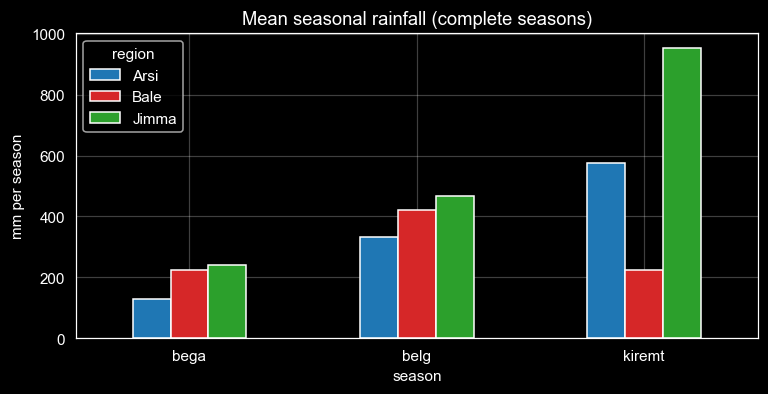

In [17]:
seasonal = md.build_seasonal(integrated)
display(seasonal.head(6))

ok = seasonal[seasonal["complete"]]
mean_rain = ok.groupby(["season", "region"])["rain_total_mm"].mean().unstack().loc[["bega", "belg", "kiremt"]]
ax = mean_rain.plot.bar(figsize=(8, 3.6), color=[COLORS[c] for c in mean_rain.columns], rot=0)
ax.set_title("Mean seasonal rainfall (complete seasons)")
ax.set_ylabel("mm per season")
savefig("merge_seasonal_rain")
plt.show()

## 5. Yearly table

,region,year,days_in_period,days_observed,rain_total_mm,wet_days,max_dry_run_days,t2m_mean_c,tmax_mean_c,vpd_mean_kpa,et0_total_mm,sm_l1_mean,sm_l2_mean,complete
0,Arsi,1981,365,365,1054.883143,122.0,57,13.783205,20.676521,0.510102,NaN,0.401104,0.413582,True
1,Arsi,1982,365,365,1220.343295,120.0,27,13.493479,19.947151,0.403130,NaN,0.421418,0.429394,True
2,Arsi,1983,365,365,1160.589980,120.0,46,13.548027,19.824986,0.397358,NaN,0.423013,0.432924,True
3,Arsi,1984,366,366,973.039362,107.0,23,13.406612,20.575902,0.540263,1379.602594,0.388320,0.396641,True
4,Arsi,1985,365,365,981.503882,122.0,29,13.317726,20.065699,0.476697,1313.464187,0.407202,0.412816,True
5,Arsi,1986,365,365,1163.428585,133.0,25,13.399041,20.220493,0.475662,1284.771755,0.410919,0.419025,True


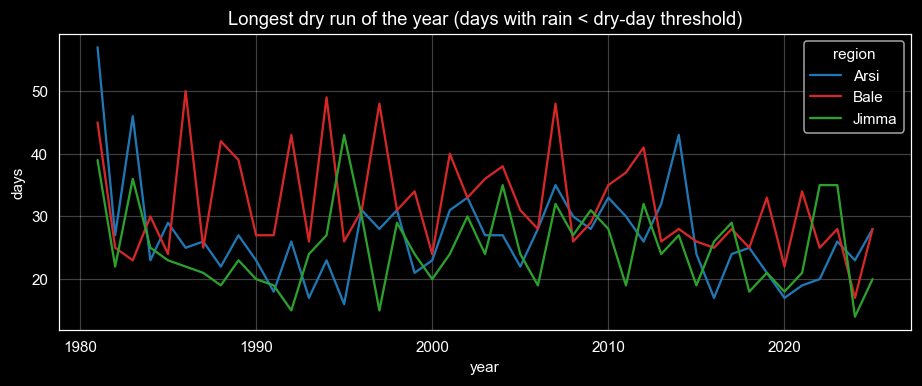

In [18]:
yearly = md.build_yearly(integrated)
display(yearly[yearly["complete"]].head(6))

pivot = yearly[yearly["complete"]].pivot(index="year", columns="region", values="max_dry_run_days")
ax = pivot.plot(figsize=(10, 3.5), color=[COLORS[c] for c in pivot.columns])
ax.set_title("Longest dry run of the year (days with rain < dry-day threshold)")
ax.set_ylabel("days")
plt.show()

## 6. Save
Same files the pipeline script writes, so either route gives the same result.

In [19]:
save_table(integrated, "integrated_daily")
save_table(seasonal, "integrated_seasonal")
save_table(yearly, "integrated_yearly")

[saved] integrated_daily.csv             rows=  50127  cols=32
[saved] integrated_seasonal.csv          rows=    414  cols=15
[saved] integrated_yearly.csv            rows=    138  cols=14


WindowsPath('C:/hackaton/ML/Data/Processed/integrated_yearly.csv')